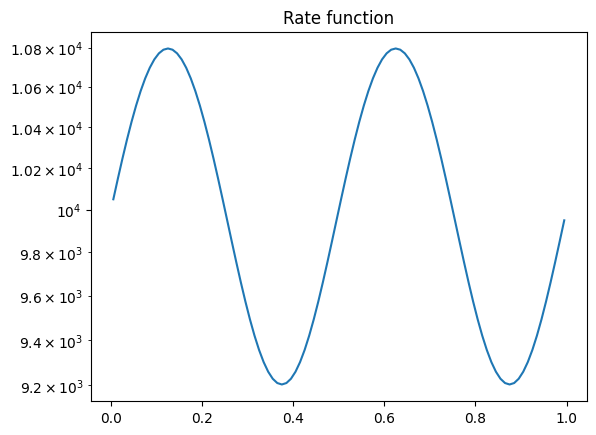

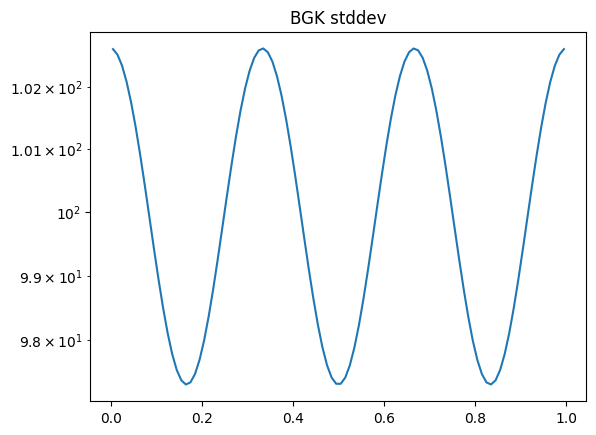

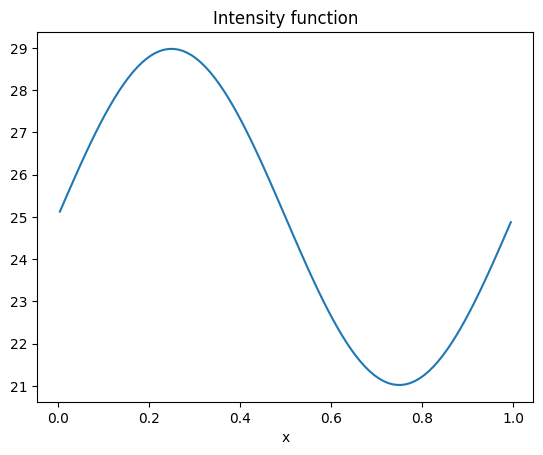

In [3]:
import numpy as np
from matplotlib import pyplot as plt
import math
import json
import subprocess
import time

config = {}

# Length of the domain
Lx = 1.0
Ly = 2.0
Lz = 2.0

# Number of cells in each direction
nx = 100
ny = 1
nz = 1

# Background parameters
ncells = nx * ny * nz
vol = Lx*Ly*Lz/nx/ny/nz

xval = np.linspace(1./nx/2., 1-1./nx/2., nx)
intensityfun = np.zeros(ncells)
for i in range(ncells):
    # intensityfun[i] = 1.0
    intensityfun[i] = (1.0 / (2.0 * np.pi) ) * np.sin(2.0 * np.pi * xval[i]) + 1.0

rate = np.zeros(ncells, dtype=np.float64)
for i in range(ncells):
    rate[i] = (1.0 / (4.0 * np.pi) ) * 10.0**4 * np.sin(4.0 * np.pi * xval[i]) + 10.0**4

bgk_stddev = np.zeros(ncells, dtype=np.float64)
for i in range(ncells):
    bgk_stddev[i] = np.sqrt((1.0 / (6.0 * np.pi) ) * 10.0**4 * np.cos(6.0 * np.pi * xval[i]) + 10.0**4)

bgk_mean_x = np.zeros(ncells, dtype=np.float64)
for i in range(ncells):
    bgk_mean_x[i] = (1.0 / (6.0 * np.pi) ) * np.sin(6.0 * np.pi * xval[i]) + 1.0

bgk_mean_y = np.zeros(ncells, dtype=np.float64)
bgk_mean_z = np.zeros(ncells, dtype=np.float64)

plt.figure()
plt.semilogy(xval, rate)
plt.title("Rate function")

plt.figure()
plt.semilogy(xval, bgk_stddev)
plt.title("BGK stddev")

plt.figure()
plt.plot(xval, intensityfun / vol)
plt.title("Intensity function")
plt.xlabel("x")
plt.show()

Simulation took 11.694952487945557 seconds
{'grid_building_time': 8.178e-06, 'num_collisions': 249941477, 'num_crossings': 201310526, 'num_kd_steps': 0, 'num_kd_to_kinetic_switches': 0, 'total_particles': 999950, 'total_time': 11.687788434, 'trace_time': 11.687780256}


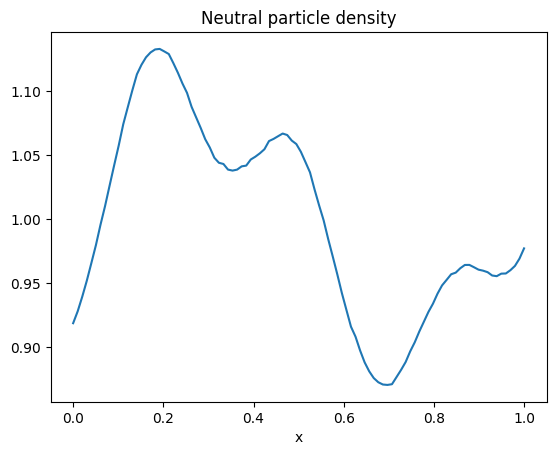

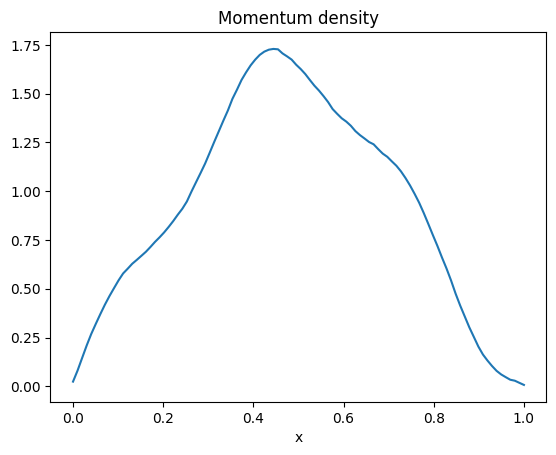

In [4]:

config["mesh"] = {
    "type": "voxel",
    "Lx": Lx,
    "Ly": Ly,
    "Lz": Lz,
    "nx": nx,
    "ny": ny,
    "nz": nz
}

config["bgk_processes"] = [
    {
        "rate": rate.tolist(),
        "bgk_stddev": bgk_stddev.tolist(),
        "bgk_mean_x": bgk_mean_x.tolist(),
        "bgk_mean_y": bgk_mean_y.tolist(),
        "bgk_mean_z": bgk_mean_z.tolist()
    }
]

config["sources"] = []
for i in range(ncells):
    config["sources"].append(
        {
            "type": "volume",
            "intensity": intensityfun[i],
            "cell_idx": i,
            "vel_mean": [bgk_mean_x[i], bgk_mean_y[i], bgk_mean_z[i]],
            "vel_stddev": bgk_stddev[i],
            "n_particles": int(1e6*intensityfun[i]/sum(intensityfun)),
        }
    )

config["boundary_conditions"] = [
    {
        "type": "specular"
    },
    {
        "type": "specular"
    },
    {
        "type": "specular"
    },
    {
        "type": "specular"
    },
    {
        "type": "specular"
    },
    {
        "type": "specular"
    },
]

if "dt" in config:
    del config["dt"]

t_final = 0.025
# t_final = 0.00005
config["t_final"] = t_final

config["max_steps"] = 10000
config["seed"] = 0

# Run the simulation
inputstring = json.dumps(config)

with open("input.json", "w") as f:
    f.write(inputstring)

start_time = time.time()
subprocess.check_output(["neptune-mc"]).decode("utf-8")
end_time = time.time()

print("Simulation took", end_time - start_time, "seconds")

with open("output.json", "r") as f:
    outputstring = f.read()

output = json.loads(outputstring)

stats = output["stats"]
print(stats)

neutral_density = np.array(output["density"]) * vol / t_final

momentum_x = np.array(output["momentum_x"]) * vol / t_final

x = np.linspace(0,Lx,nx)


plt.plot(x, neutral_density)
# plt.plot(x, intensityfun)
plt.title("Neutral particle density")
plt.xlabel("x")
plt.show()

plt.plot(x, momentum_x)
plt.title("Momentum density")
plt.xlabel("x")
plt.show()

Simulation took 4.9448888301849365 seconds


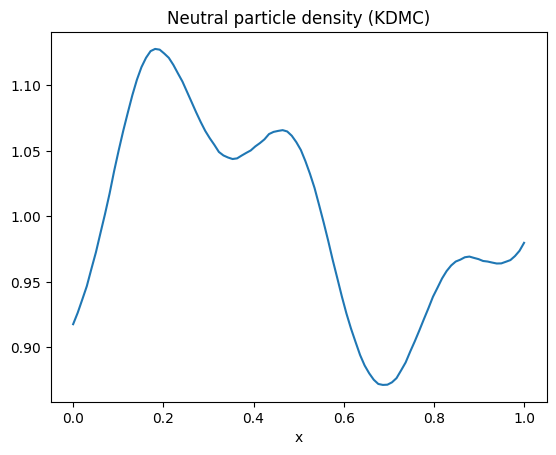

In [5]:
##
## Part 2, KDMC
##

fluid_boundary_conditions = [
    {
        "alpha": -bgk_mean_x[0],
        "beta": -bgk_stddev[0]**2/ rate[0],
        "gamma": 0
    },
    {
        "alpha": -bgk_mean_y[0],
        "beta": -bgk_stddev[0]**2/ rate[0],
        "gamma": 0
    },
    {
        "alpha": -bgk_mean_z[0],
        "beta": -bgk_stddev[0]**2/ rate[0],
        "gamma": 0
    },
    {
        "alpha": bgk_mean_x[ncells-1],
        "beta": -bgk_stddev[ncells-1]**2/ rate[ncells-1],
        "gamma": 0
    },
    {
        "alpha": bgk_mean_y[ncells-1],
        "beta": -bgk_stddev[ncells-1]**2/ rate[ncells-1],
        "gamma": 0
    },
    {
        "alpha": bgk_mean_z[ncells-1],
        "beta": -bgk_stddev[ncells-1]**2/ rate[ncells-1],
        "gamma": 0
    },
]

config_kd = config.copy()

config_kd["fluid_boundary_conditions"] = fluid_boundary_conditions

config_kd["dt"] = 1.0e-3

inputstring = json.dumps(config_kd)
with open("input.json", "w") as f:
    f.write(inputstring)

start_time = time.time()
subprocess.check_output(["neptune-mc"]).decode("utf-8")
end_time = time.time()

print("Simulation took", end_time - start_time, "seconds")

with open("output.json", "r") as f:
    outputstring = f.read()

output = json.loads(outputstring)

neutral_density_kd = np.array(output["density"]) * vol / t_final

x = np.linspace(0,Lx,nx)

plt.plot(x, neutral_density_kd)
# plt.plot(x, intensityfun)
plt.title("Neutral particle density (KDMC)")
plt.xlabel("x")
plt.show()

In [6]:

##
## Part 3, finite volume solver
##

fv_density = np.zeros(ncells, dtype=np.float64)

for i in range(ncells):
    fv_density[i] = intensityfun[i] / vol

diffusion_rate = np.zeros(ncells, dtype=np.float64)
for i in range(ncells):
    diffusion_rate[i] = 1/rate[i]

diffusion_factor = np.zeros(ncells, dtype=np.float64)
for i in range(ncells):
    diffusion_factor[i] = bgk_stddev[i]**2

config_fluid = config.copy()


config_fluid["density"] = fv_density.tolist()
config_fluid["diffusion_rate"] = diffusion_rate.tolist()
config_fluid["diffusion_factor"] = diffusion_factor.tolist()
config_fluid["advection_x"] = bgk_mean_x.tolist()
config_fluid["advection_y"] = bgk_mean_y.tolist()
config_fluid["advection_z"] = bgk_mean_z.tolist()
config_fluid["t_final"] = t_final
config_fluid["dt"] = 1.0e-6

config_fluid["boundary_conditions"] = fluid_boundary_conditions

inputstring = json.dumps(config_fluid)

with open("input.json", "w") as f:
    f.write(inputstring)

start_time = time.time()
subprocess.check_output(["neptune-fv"]).decode("utf-8")
end_time = time.time()


with open("output.json", "r") as f:
    outputstring = f.read()

output = json.loads(outputstring)

stats = output["stats"]
print(stats)

neutral_density_fv = np.array(output["density_integral"]) * vol / t_final




{'grid_building_time': 7.466e-06, 'num_collisions': 0, 'num_crossings': 0, 'num_kd_steps': 0, 'num_kd_to_kinetic_switches': 0, 'total_particles': 0, 'total_time': 0.488382972, 'trace_time': 0.488375506}


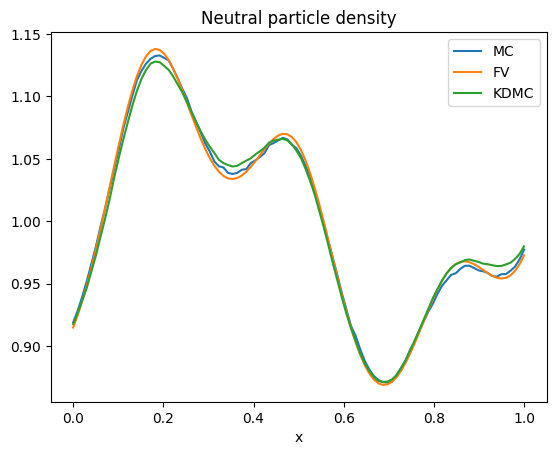

In [7]:

plt.figure()
plt.plot(x, neutral_density, label="MC")
plt.plot(x, neutral_density_fv, label="FV")
plt.plot(x, neutral_density_kd, label="KDMC")
# plt.plot(x, intensityfun)
plt.title("Neutral particle density")
plt.xlabel("x")
plt.legend()
plt.show()

